# 01 Olivine (EPMA, session 01/03/2017)

Processing follows the course steps 1 to 10; each step has its own section and the reason for every decision is written above the code that applies it.

In [1]:
# --- config ---
from pathlib import Path
import sys, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt
warnings.filterwarnings("ignore", message="Unknown extension")      # harmless openpyxl warning on Standards.xlsx
sys.path.insert(0, "src")
from geohelpers import read_jeol, read_dl, read_cal, read_ref, mean_2sd

DATA, OUT, FIG = Path("data"), Path("outputs"), Path("figures/olivine")
OUT.mkdir(exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
STD = "SC-Olivine"
OX = ["SiO2", "Al2O3", "Cr2O3", "FeO", "MnO", "MgO", "CaO", "NiO"]
PER_BRACKET = 3                                    # SC-Olivine was measured 3 times at each standard bracket
pd.set_option("display.width", 200, "display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight", "font.size": 9})

## Steps 1 and 2. One table: oxides and Fo/Fa

`_oxide` (wt%) and `_ratios` (Fo, Fa in mol%) joined on the analysis number; Comment first, then the oxides. The last number in a Comment is the spot; the rest identifies the grain (from the .docx).

In [2]:
ox = read_jeol(DATA / "ol_01032017_oxide.txt")
rt = read_jeol(DATA / "ol_01032017_ratios.txt")
assert ox.Comment.equals(rt.Comment)                                  # same analyses in the same order
ol = ox.merge(rt[["No.", "Fo+M", "Fa+M"]], on="No.")
ol["Grain"] = ol.Comment.str.rsplit("_", n=1).str[0]
ol["Sample"] = ol.Comment.str.split("_").str[0]
ol = ol[["No.", "Comment", "Sample", "Grain"] + OX + ["Total", "Fo+M", "Fa+M"]]
is_std = ol.Comment.eq(STD)

print(len(ol), "analyses;", STD, is_std.sum(), "times at No.", ol.loc[is_std, "No."].tolist())
print(ol[~is_std].groupby("Sample").agg(grains=("Grain", "nunique"), spots=("No.", "size")).to_string())

128 analyses; SC-Olivine 15 times at No. [1, 2, 3, 25, 26, 27, 59, 60, 61, 89, 90, 91, 126, 127, 128]
                 grains  spots
Sample                        
UnkA-C20-S2-1MI       7     21
UnkA-C20-S2-3MI       4     12
UnkA-C21MI           26     80


## Step 3. Plot the standard and remove obvious outliers by eye

Each oxide of SC-Olivine against analysis number, with the reference value (loaded here so the plots can show it). A point is removed only when it is clearly separated from the other 14 and pulls the mean. A shift shared by a whole bracket is kept: it affected the samples measured at the same time too.

**Removed** (decided from the plots below):
- NiO, No. 90: 0.283 wt% against 0.34 to 0.38 for the other analyses.
- Cr₂O₃, No. 1: 0.031 wt% against 0.005 to 0.022 (Cr₂O₃ is close to its detection limit, about 0.008 wt%).
- Al₂O₃, No. 128: 0.044 wt% against 0.029 to 0.039.

**Kept:** SiO₂ is 39.5 to 39.8 wt% in the first three brackets, then rises to 40.2 to 40.3 (No. 89 to 91) and 41.0 to 41.3 (No. 126 to 128). This is a trend through the session, not single bad points; it is discussed under data quality.

**Reference values:** `Standards.xlsx`, except SiO₂, MgO and FeO, which come from `ol_01032017_std-cnd.txt`: the same values with more digits, and exactly the values the instrument was calibrated on.

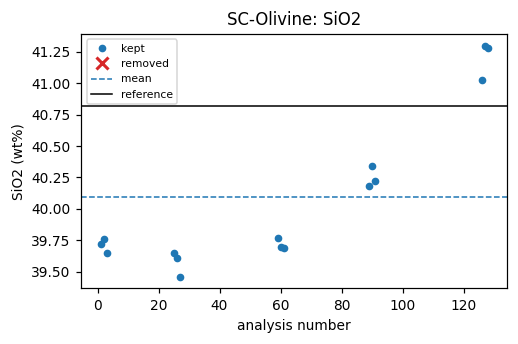

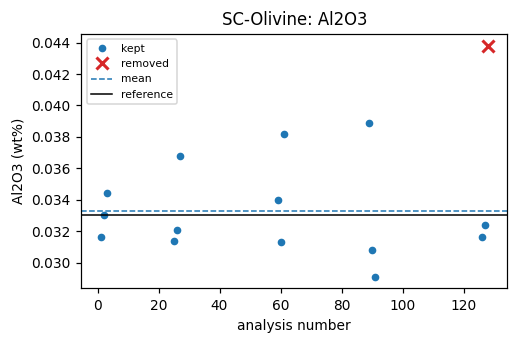

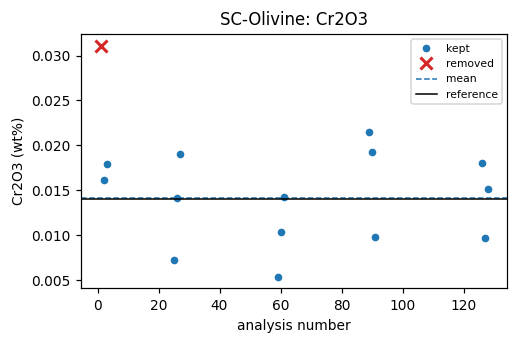

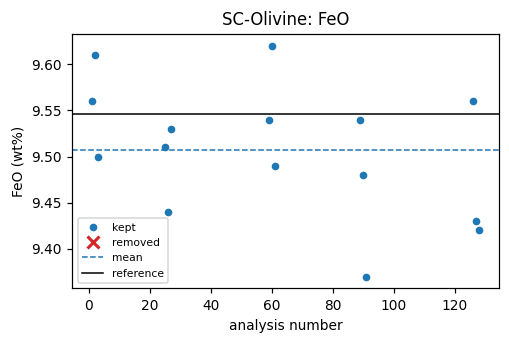

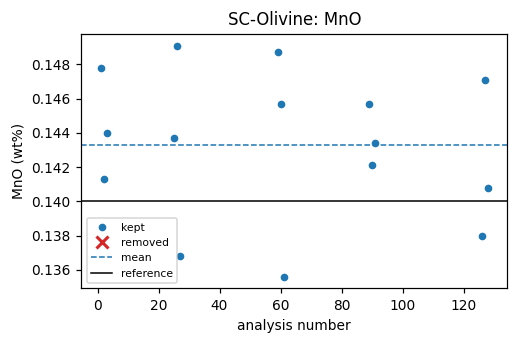

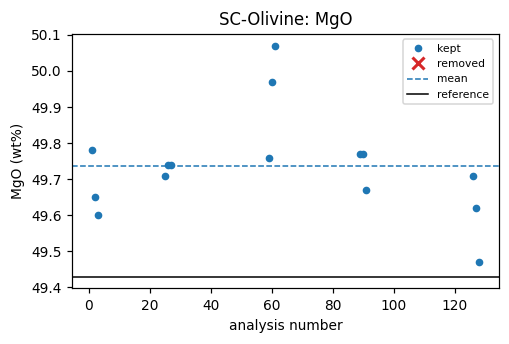

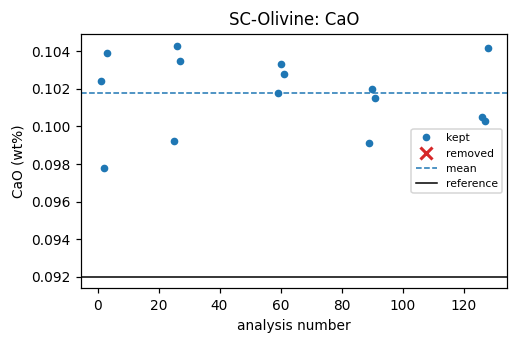

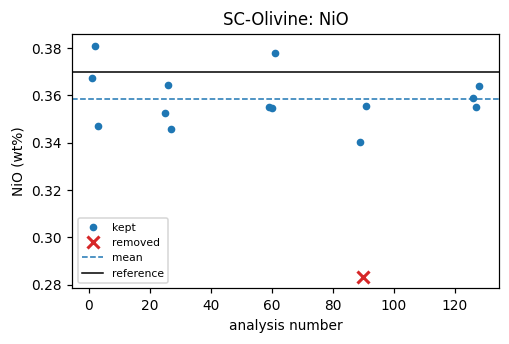

In [3]:
ref = read_ref(DATA / "Standards.xlsx", {"SC_Olivine": STD}).loc[STD]
cal = read_cal(DATA / "ol_01032017_std-cnd.txt").query("standard == @STD").set_index("oxide")["value"]
GT = ref[OX].astype(float)
GT[cal.index] = cal                                                  # std-cnd values replace the xlsx where available
SRC = pd.Series(np.where(GT.index.isin(cal.index), "std-cnd", "Standards.xlsx"), index=OX)
FO_REF = ref["Fo corr"]

std = ol[is_std].set_index("No.")
DROP = {"NiO": [90], "Cr2O3": [1], "Al2O3": [128]}
clean = std[OX].copy()
for el, nos in DROP.items():
    clean.loc[nos, el] = np.nan

def plot_std(el, fname=None):
    fig, ax = plt.subplots(figsize=(5, 3))
    keep = clean[el].notna()
    ax.plot(std.index[keep], std.loc[keep, el], "o", ms=4, label="kept")
    ax.plot(std.index[~keep], std.loc[~keep, el], "x", ms=8, mew=2, color="C3", label="removed")
    ax.axhline(clean[el].mean(), ls="--", lw=1, color="C0", label="mean")
    ax.axhline(GT[el], color="k", lw=1, label="reference")
    ax.set(xlabel="analysis number", ylabel=f"{el} (wt%)", title=f"{STD}: {el}")
    ax.legend(fontsize=7)
    if fname: fig.savefig(fname)
    plt.show()

for el in OX:
    plot_std(el, FIG / f"std_{el}.png")

## Step 4. Mean, SD and correction factor; correct every analysis

CF = mean / reference, from the analyses kept in step 3. Every analysis, samples and standards, is divided by CF; the total is recomputed as the sum of the corrected oxides. `SD_all` is the SD before the removals, to show their effect.

In [4]:
cf = pd.DataFrame({"n": clean.count(), "mean": clean.mean(), "SD": clean.std(), "SD_all": std[OX].std(),
                   "reference": GT, "source": SRC})
cf["CF"] = cf["mean"] / cf["reference"]
print(cf.round(4).to_string())

corr = ol.copy()
corr[OX] = ol[OX] / cf["CF"]
corr["Total"] = corr[OX].sum(axis=1)

with pd.ExcelWriter(OUT / "olivine_step4_standards.xlsx") as xw:
    std.reset_index().to_excel(xw, sheet_name="SC-Olivine raw", index=False)
    cf.to_excel(xw, sheet_name="correction factors")
    ol.to_excel(xw, sheet_name="all raw", index=False)
    corr.to_excel(xw, sheet_name="all corrected", index=False)

        n     mean      SD  SD_all  reference          source      CF
SiO2   15  40.0907  0.6283  0.6283    40.8158         std-cnd  0.9822
Al2O3  14   0.0333  0.0029  0.0039     0.0330  Standards.xlsx  1.0078
Cr2O3  14   0.0142  0.0049  0.0065     0.0140  Standards.xlsx  1.0107
FeO    15   9.5067  0.0705  0.0705     9.5457         std-cnd  0.9959
MnO    15   0.1433  0.0042  0.0042     0.1400  Standards.xlsx  1.0237
MgO    15  49.7353  0.1432  0.1432    49.4299         std-cnd  1.0062
CaO    15   0.1018  0.0020  0.0020     0.0920  Standards.xlsx  1.1062
NiO    14   0.3586  0.0116  0.0224     0.3700  Standards.xlsx  0.9691


## Step 5. Flag correction factors outside ±5 %

A CF more than 5 % from 1 means the session measured that oxide more than 5 % away from its reference value; those oxides are reported.

       mean  reference      CF
CaO  0.1018      0.092  1.1062


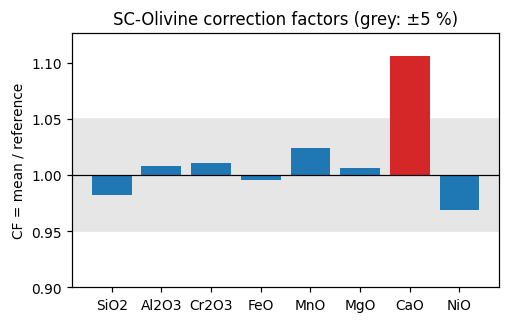

In [5]:
cf["flag"] = (cf.CF - 1).abs() > 0.05
print(cf.loc[cf.flag, ["mean", "reference", "CF"]].round(4).to_string())

fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(cf.index, cf.CF - 1, bottom=1, color=np.where(cf.flag, "C3", "C0"))
ax.set_ylim(min(0.9, cf.CF.min() - 0.02), max(1.1, cf.CF.max() + 0.02))
ax.axhspan(0.95, 1.05, color="0.9", zorder=0); ax.axhline(1, color="k", lw=0.8)
ax.set(ylabel="CF = mean / reference", title=f"{STD} correction factors (grey: ±5 %)")
fig.savefig(FIG / "cf.png"); plt.show()

## Step 6. Accuracy from a held-out standard

After the correction the SC-Olivine mean equals its reference by construction, so its accuracy would always be 0 %. Instead the CF is recomputed from the first two analyses of each bracket and applied to the third, which was not used to compute it. The deviation of those held-out analyses from the reference is the accuracy.

In [6]:
is_test = pd.Series(np.arange(len(std)) % PER_BRACKET == PER_BRACKET - 1, index=std.index)
cf_train = clean[~is_test].mean() / GT
test = clean[is_test] / cf_train
acc = pd.DataFrame({"n_train": clean[~is_test].count(), "n_test": test.count(), "CF_train": cf_train,
                    "test_mean": test.mean(), "reference": GT, "accuracy_pct": 100 * (test.mean() / GT - 1)})
print("held-out analyses: No.", std.index[is_test].tolist())
print(acc.round(4).to_string())

held-out analyses: No. [3, 27, 61, 91, 128]
       n_train  n_test  CF_train  test_mean  reference  accuracy_pct
SiO2        10       5    0.9826    40.7690    40.8158       -0.1147
Al2O3       10       4    0.9912     0.0349     0.0330        5.8545
Cr2O3        9       5    0.9675     0.0158     0.0140       12.5185
FeO         10       5    0.9983     9.4786     9.5457       -0.7031
MnO         10       5    1.0351     0.1354     0.1400       -3.3122
MgO         10       5    1.0064    49.3921    49.4299       -0.0764
CaO         10       5    1.0986     0.0939     0.0920        2.0877
NiO          9       5    0.9697     0.3693     0.3700       -0.1951


## Step 7. Fo check

`Fo+M` in `_ratios` is 100·Mg/(Mg+Fe) in moles, computed by the instrument software from the same MgO and FeO. It is therefore not an independent measurement and cannot be used to recalibrate MgO or FeO: recomputing it from the raw oxides gives the same number. What changes Fo is only the correction of MgO and FeO from step 4.

In [7]:
fo = lambda d: 100 * (d.MgO / 40.304) / (d.MgO / 40.304 + d.FeO / 71.844)
corr["Fo"] = fo(corr)
d = corr.Fo - ol["Fo+M"]
print(f"max |Fo from raw oxides - Fo+M| = {(fo(ol) - ol['Fo+M']).abs().max():.3f} mol%")
print(f"correction changes Fo by {d.mean():+.3f} mol% on average ({d.min():+.3f} to {d.max():+.3f})")
f = corr.loc[is_std, "Fo"]
print(f"SC-Olivine Fo after correction: {f.mean():.2f} ± {2 * f.std():.2f} (2SD), reference {FO_REF}")

max |Fo from raw oxides - Fo+M| = 0.009 mol%
correction changes Fo by -0.138 mol% on average (-0.173 to -0.084)
SC-Olivine Fo after correction: 90.23 ± 0.12 (2SD), reference 90.22


## Step 8. Precision and accuracy after correction (2σ)

Precision: 2SD and 2RSD of the corrected SC-Olivine analyses (removed points excluded). Accuracy: the held-out test of step 6.

In [8]:
sc = clean / cf.CF
qc = pd.DataFrame({"n": sc.count(), "mean": sc.mean(), "2SD": 2 * sc.std(), "reference": GT,
                   "precision_2RSD_pct": 200 * sc.std() / sc.mean(), "accuracy_pct": acc.accuracy_pct,
                   "CF": cf.CF, "CF_flag": cf.flag})
print(qc.round(4).to_string())

        n     mean     2SD  reference  precision_2RSD_pct  accuracy_pct      CF  CF_flag
SiO2   15  40.8158  1.2793    40.8158              3.1342       -0.1147  0.9822    False
Al2O3  14   0.0330  0.0057     0.0330             17.4067        5.8545  1.0078    False
Cr2O3  14   0.0140  0.0098     0.0140             69.6788       12.5185  1.0107    False
FeO    15   9.5457  0.1415     9.5457              1.4826       -0.7031  0.9959    False
MnO    15   0.1400  0.0083     0.1400              5.9086       -3.3122  1.0237    False
MgO    15  49.4299  0.2846    49.4299              0.5757       -0.0764  1.0062    False
CaO    15   0.0920  0.0036     0.0920              3.9663        2.0877  1.1062     True
NiO    14   0.3700  0.0239     0.3700              6.4605       -0.1951  0.9691    False


## Step 9. Samples: clean copy, totals, obviously wrong analyses, detection limits

Standards removed. Totals outside 98 to 102 wt% are flagged: above 102 is a problem and is reported; below 98 is not explained by volatiles here, because olivine contains none. Analyses that are obviously wrong for their grain would be flagged and left out of the figures. Values below the detection limit of their own analysis (from `_all`) are flagged, never removed; the detection limits also explain the large relative scatter of the trace oxides.

total_flag
98-102    71
> 102     42
 No.             Comment  Total
  35 UnkA-C20-S2-3MI_3_2 102.00
  36 UnkA-C20-S2-3MI_3_3 102.11
  40      UnkA-C21MI_1_1 102.14
  45      UnkA-C21MI_2_3 102.13
  49      UnkA-C21MI_4_1 102.55
  50      UnkA-C21MI_4_2 102.45
  51      UnkA-C21MI_4_3 102.40
  53      UnkA-C21MI_5_1 102.66
  54      UnkA-C21MI_5_2 102.25
  62      UnkA-C21MI_7_1 102.07
  65      UnkA-C21MI_8_1 102.08
  66      UnkA-C21MI_8_2 102.00
  68      UnkA-C21MI_9_1 102.44
  70      UnkA-C21MI_9_3 102.36
  74     UnkA-C21MI_11_1 102.35
  75     UnkA-C21MI_11_2 102.38
  76     UnkA-C21MI_11_3 102.40
  77     UnkA-C21MI_12_1 102.50
  78     UnkA-C21MI_12_2 102.32
  79     UnkA-C21MI_12_3 102.41
  80     UnkA-C21MI_13_1 102.27
  81     UnkA-C21MI_13_2 102.59
  82     UnkA-C21MI_13_3 102.32
  84     UnkA-C21MI_14_2 102.51
  85     UnkA-C21MI_14_3 102.65
  95     UnkA-C21MI_17_1 102.23
  96     UnkA-C21MI_17_2 102.24
  97     UnkA-C21MI_17_3 102.21
  98     UnkA-C21MI_18_1 102.52
  9

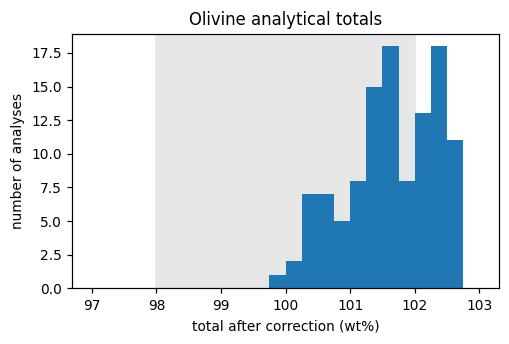

In [9]:
smp = corr[~is_std].copy()
smp["total_flag"] = np.select([smp.Total < 98, smp.Total > 102], ["< 98", "> 102"], "")
print(smp.total_flag.replace("", "98-102").value_counts().to_string())
print(smp.loc[smp.total_flag != "", ["No.", "Comment", "Total"]].round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(5, 3))
ax.hist(smp.Total, bins=np.arange(97, 103.01, 0.25))
ax.axvspan(98, 102, color="0.9", zorder=0)
ax.set(xlabel="total after correction (wt%)", ylabel="number of analyses", title="Olivine analytical totals")
fig.savefig(FIG / "totals.png"); plt.show()

Visual check of the sample analyses, oxide by oxide against analysis number. No analysis is obviously wrong for its grain: there is no sign of glass or inclusion contamination (Al₂O₃ at most 0.05 wt%, CaO at most 0.37 wt% after correction), so nothing is excluded.

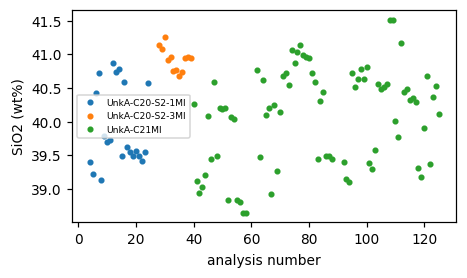

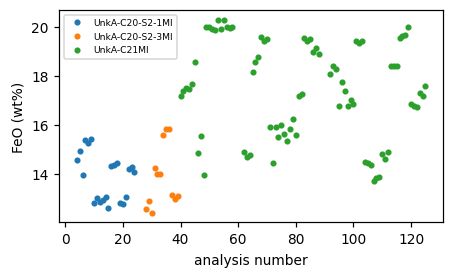

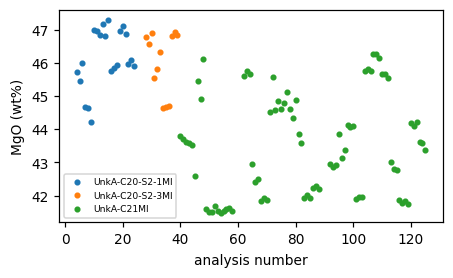

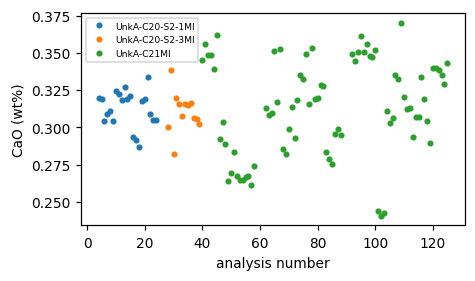

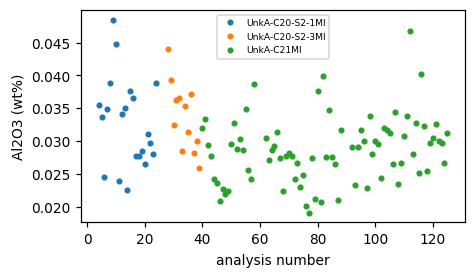

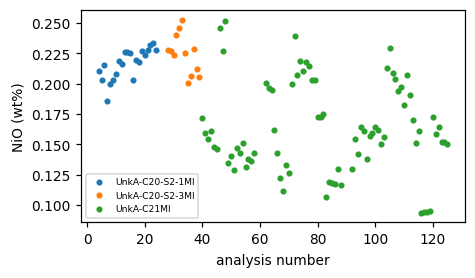

In [10]:
for el in ["SiO2", "FeO", "MgO", "CaO", "Al2O3", "NiO"]:
    fig, ax = plt.subplots(figsize=(4.5, 2.5))
    for i, (s, d) in enumerate(smp.groupby("Sample")):
        ax.plot(d["No."], d[el], "o", ms=3, color=f"C{i}", label=s)
    ax.set(xlabel="analysis number", ylabel=f"{el} (wt%)"); ax.legend(fontsize=6)
    plt.show()

BAD = {}                                                             # No.: reason; none found
smp["exclude"] = smp["No."].isin(BAD)

In [11]:
dl = read_dl(DATA / "ol_01032017_all.txt")[OX]
below = smp[OX].lt(dl.loc[smp["No."]].values)
smp[[f"{el}_bdl" for el in OX]] = below.values
dlt = pd.DataFrame({"DL_median": dl.loc[smp["No."]].median(), "sample_median": smp[OX].median(),
                    "n_below_DL": below.sum(), "n": len(smp)})
print("detection limits, wt% oxide:"); print(dlt.round(4).to_string())

detection limits, wt% oxide:
       DL_median  sample_median  n_below_DL    n
SiO2      0.0128        40.2857           0  113
Al2O3     0.0045         0.0294           0  113
Cr2O3     0.0075         0.0126          36  113
FeO       0.0139        16.0054           0  113
MnO       0.0045         0.2916           0  113
MgO       0.0065        44.3559           0  113
CaO       0.0020         0.3151           0  113
NiO       0.0083         0.1828           0  113


## Step 10. Final data

Corrected sample analyses with their flags, and grain averages (n, mean, 2SD) of the analyses not excluded. Ready for the figures and the paper table.

In [12]:
fin = smp[~smp.exclude]
grains = mean_2sd(fin, ["Sample", "Grain"], OX + ["Total", "Fo"])
with pd.ExcelWriter(OUT / "olivine_final.xlsx") as xw:
    smp.to_excel(xw, sheet_name="samples corrected", index=False)
    grains.reset_index().to_excel(xw, sheet_name="grain means", index=False)
    qc.to_excel(xw, sheet_name="standard QC")
    acc.to_excel(xw, sheet_name="hold-out accuracy")
    dlt.to_excel(xw, sheet_name="detection limits")
    sc.assign(Sample=STD).reset_index().to_excel(xw, sheet_name="standards corrected", index=False)
    GT.rename("reference").to_frame().T.rename(index={"reference": STD}).to_excel(xw, sheet_name="references")
print(len(fin), "analyses,", len(grains), "grains")
print(grains.round(3).head().to_string())

113 analyses, 37 grains
                                   n    SiO2  SiO2_2SD  Al2O3  Al2O3_2SD  Cr2O3  Cr2O3_2SD     FeO  FeO_2SD    MnO  MnO_2SD     MgO  MgO_2SD    CaO  CaO_2SD    NiO  NiO_2SD    Total  Total_2SD      Fo  Fo_2SD
Sample          Grain                                                                                                                                                                                           
UnkA-C20-S2-1MI UnkA-C20-S2-1MI_1  3  39.682     1.306  0.031      0.012  0.029      0.012  14.493    0.971  0.235    0.036  45.731    0.567  0.314    0.017  0.210    0.013  100.724      0.843  84.905   1.017
                UnkA-C20-S2-1MI_2  3  39.878     1.606  0.041      0.014  0.011      0.013  15.366    0.153  0.244    0.006  44.515    0.518  0.308    0.007  0.196    0.018  100.560      1.811  83.776   0.272
                UnkA-C20-S2-1MI_3  3  40.099     1.346  0.034      0.021  0.039      0.012  12.909    0.206  0.206    0.012  46.947    0.169